<a href="https://colab.research.google.com/github/tanwistha2010/KNN_MNISTDigitClassification/blob/main/MNISTDataset_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libraries

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load MNIST handwritten digit dataset

print("Loading MNIST dataset...")

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

# Separate features and labels
X = mnist.data
y = mnist.target.astype(int)

print("Dataset loaded successfully!")

print("Total images:", X.shape[0])
print("Total features:", X.shape[1])
print("Total labels:", y.shape[0])

Loading MNIST dataset...
Dataset loaded successfully!
Total images: 70000
Total features: 784
Total labels: 70000


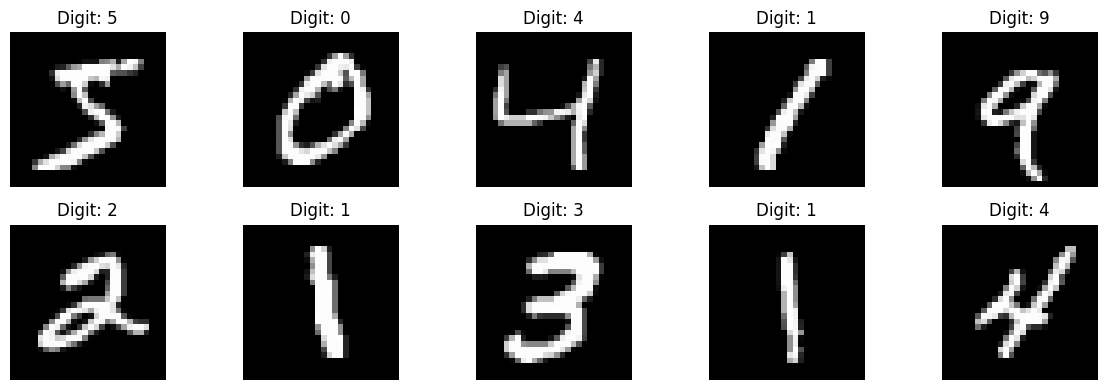

In [ ]:
# Display first 10 handwritten digit images

plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X[i].reshape(28, 28), cmap='gray')

    plt.title("Digit: " + str(y[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Normalize pixel values between 0 and 1

X = X / 255.0

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=10000,
    test_size=2000,
    random_state=42,
    stratify=y
)

print("Data preprocessing completed!")

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Data preprocessing completed!
Training data: (10000, 784)
Testing data: (2000, 784)


In [ ]:
# Create KNN model

knn = KNeighborsClassifier(n_neighbors=3)

print("KNN classifier created successfully!")

KNN classifier created successfully!


In [ ]:
# Train the KNN model

print("Training the model...")

knn.fit(X_train, y_train)

print("Model training completed successfully!")

Training the model...
Model training completed successfully!


In [ ]:
# Predict digits using testing data

y_pred = knn.predict(X_test)

print("Prediction completed!")

print("First 10 actual values:")
print(y_test[:10])

print("First 10 predicted values:")
print(y_pred[:10])

Prediction completed!
First 10 actual values:
[8 4 1 1 8 5 4 5 5 5]
First 10 predicted values:
[8 4 1 1 8 5 4 5 5 5]


In [ ]:
# Calculate accuracy

accuracy = accuracy_score(y_test, y_pred)

print("KNN Model Accuracy:", round(accuracy * 100, 2), "%")

KNN Model Accuracy: 95.05 %


In [ ]:
# Classification report

print("Classification Report:\n")

print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       197
           1       0.91      1.00      0.95       225
           2       0.97      0.94      0.96       200
           3       0.91      0.93      0.92       204
           4       0.96      0.95      0.96       195
           5       0.93      0.92      0.93       180
           6       0.98      0.99      0.98       197
           7       0.94      0.94      0.94       208
           8       0.99      0.87      0.92       195
           9       0.95      0.96      0.96       199

    accuracy                           0.95      2000
   macro avg       0.95      0.95      0.95      2000
weighted avg       0.95      0.95      0.95      2000



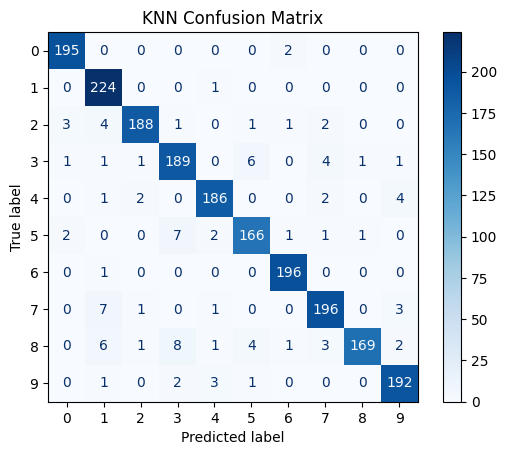

In [ ]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

display.plot(cmap='Blues', values_format='d')

plt.title("KNN Confusion Matrix")
plt.show()

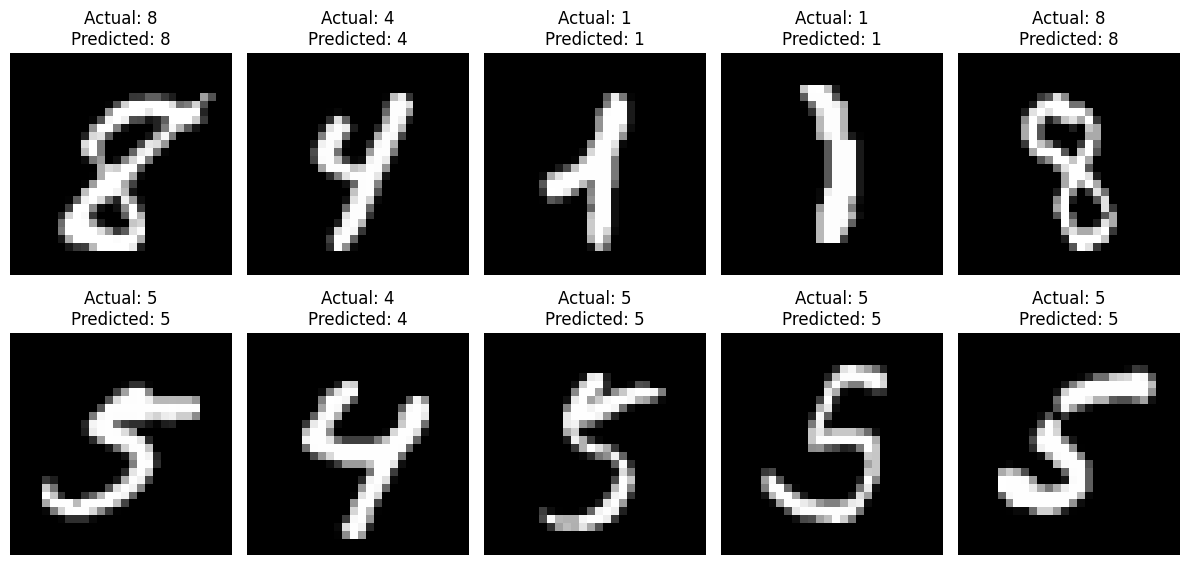

In [ ]:
# Select 10 random test images

plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    # Predict digit
    prediction = knn.predict([X_test[i]])[0]

    # Display image
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        "Actual: " + str(y_test[i]) +
        "\nPredicted: " + str(prediction)
    )

    plt.axis('off')

plt.tight_layout()
plt.show()